# 02b — Auxiliary data

**Task:** M1-T07 (auxiliary data ingestion).

**Purpose:** put elevation, land cover, rainfall and aridity on the same grid as the Sentinel-2 composites of M1-T06, so that M1-T08 can attach them to every 100 m cell, and show that they line up.

**Inputs:** `config/project.yaml` (`extraction`, `aux_data`, `climate_data`), `config/aois.geojson`, `reports/results/m1_aoi_climate.csv` (AOI aridity from M1-T02); optionally the cached composites in `data/raw/<aoi_id>/` (background of the overlay only).

**Outputs** (local, each with a provenance sidecar):
- `data/raw/aux/dem/<aoi_id>/dem_20m_*.tif`: Copernicus DEM GLO-30, bands `elevation_m`, `slope_deg`, `aspect_deg`, on the exact 20 m grid of the extraction window;
- `data/raw/aux/worldcover/<aoi_id>/worldcover_<year>_10m_*.tif`: ESA WorldCover 2020 and 2021, 10 m, nested 2 × 2 in the 20 m grid;
- `data/raw/aux/chirps/<aoi_id>/monthly_grid_*.tif` and `data/raw/aux/eto/<aoi_id>/monthly_grid_*.tif`: CHIRPS v3 rainfall and Hobbins ETo, one band per month of the study period, native 0.05°;
- committed: `reports/results/m1_aux_registration.csv`, `m1_aux_summary.csv`; figures `reports/figures/m1_aux_overlay.png`, `m1_aux_overlay_zoom.png`.

**Sentinel Hub:** none. All four sources are open data (Planetary Computer STAC with signed URLs, and the Climate Hazards Center server), with no quota.

**Run time:** about 5–15 minutes on the first run (mostly the 168 monthly climate files, read two at a time to stay polite to the CHC server); seconds once cached. A failed climate run keeps what it got and resumes.

In [1]:
%load_ext autoreload
%autoreload 2

import logging
import platform
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

import desertification
from desertification.aux_data import (
    WORLDCOVER_CLASSES, aridity_grid, block_class_fractions, block_mode, busiest_block, cell_centres_lonlat,
    class_edges, climate_monthly_grids, dem_layers, fetch_aux_per_aoi, find_composite, grid_lines_projected,
    grid_transform, grids_nested, hillshade, read_tif, sample_nearest, window_bounds_wgs84, worldcover_layer,
)
from desertification.config import get_path, load_aois, load_config
from desertification.extraction import extraction_window
from desertification.viz import plot_aux_overlay, stretch_true_colour

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
logging.getLogger("rasterio").setLevel(logging.ERROR)  # GDAL's own HTTP 429 retry chatter; failures still raise
plt.rcParams["figure.dpi"] = 50  # small inline previews; report figures are saved at 150 dpi
cfg = load_config()
SEED = cfg["project"]["seed"]
rng = np.random.default_rng(SEED)
aux, ext = cfg["aux_data"], cfg["extraction"]
RES, CELL = cfg["grid"]["pixel_resolution_m"], cfg["grid"]["cell_size_m"]
RESULTS, FIGURES = get_path(cfg, "results"), get_path(cfg, "figures")
print(f"Python {platform.python_version()} | desertification {desertification.__version__} | "
      f"rasterio {rasterio.__version__} | numpy {np.__version__}")

Python 3.12.3 | desertification 0.1.0 | rasterio 1.5.2 | numpy 2.5.5


## 1. The target grid

Every layer is aligned to the grid the M1-T06 composites were requested on: the 10 km extraction window of each AOI (with the per-AOI offsets in `extraction.window_offsets_m`), in the AOI's UTM zone, with 20 m pixels whose origin is the window's north-west corner. Sentinel Hub returns exactly this grid for a bbox and resolution, so a layer on it needs no further resampling in M1-T08. The 100 m analysis cells are 5 × 5 of these pixels.

In [2]:
aois = {f["properties"]["aoi_id"]: f["properties"] for f in load_aois(cfg)["features"]}
offsets = ext.get("window_offsets_m") or {}
snap = cfg["aoi_selection"]["snap_m"]
windows = {k: extraction_window(p["bbox_utm"], ext["window_m"], snap, offsets.get(k, (0, 0))) for k, p in aois.items()}
grids = {k: grid_transform(w, RES) for k, w in windows.items()}
pd.DataFrame([{"aoi_id": k, "utm_epsg": aois[k]["utm_epsg"], "window_utm": windows[k],
               "width_px": grids[k][1], "height_px": grids[k][2]} for k in aois])

,aoi_id,utm_epsg,window_utm,width_px,height_px
0,aral,32641,"[258600.0, 4984300.0, 268600.0, 4994300.0]",500,500
1,ferlo,32628,"[548600.0, 1708700.0, 558600.0, 1718700.0]",500,500
2,fakara,32631,"[451700.0, 1487500.0, 461700.0, 1497500.0]",500,500
3,kubuqi,32649,"[335000.0, 4446000.0, 345000.0, 4456000.0]",500,500
4,urmia,32638,"[512700.0, 4168500.0, 522700.0, 4178500.0]",500,500
5,erg,32631,"[264900.0, 3382700.0, 274900.0, 3392700.0]",500,500


## 2. Elevation and land cover (Planetary Computer)

**Why these products.** Copernicus DEM GLO-30 is the global DEM that Sentinel Hub and the ESA services use; WorldCover is the only global 10 m land-cover map made from Sentinel-1/2 itself, for 2020 and 2021 (inside our early period). Both are free and open (licences in `docs/REFERENCES.md`).

**Resampling choices.**
- *DEM:* bilinear from ~30 m to the 20 m grid. Elevation is continuous, and nearest-neighbour would produce 30 m steps that show up as false slope stripes. Slope and aspect use Horn's 3 × 3 method at 20 m. The DEM is read one pixel wider than the window, so border pixels get true slopes.
- *WorldCover:* nearest-neighbour (class codes cannot be averaged) onto a **10 m** grid with the same origin as the 20 m grid. Keeping 10 m avoids losing classes, and because the grids nest exactly, M1-T08 can compute class fractions per 100 m cell (10 × 10 pixels) or a 20 m majority class without another resampling step.

Both datasets are read as windows of cloud-optimised GeoTIFFs, so only a few MB are transferred per AOI. Each AOI is cached on its own, so a failure only costs the AOIs that failed, and they are retried with backoff.

In [3]:
DOWNLOAD_AUX = True  # open data, no quota; cached after the first run (set False to work offline)

def fetch_dem(aoi_id):
    return dem_layers(cfg, aoi_id, windows[aoi_id], aois[aoi_id]["utm_epsg"], RES, allow_download=DOWNLOAD_AUX)

def fetch_wc(year):
    def one(aoi_id):
        return worldcover_layer(cfg, aoi_id, windows[aoi_id], aois[aoi_id]["utm_epsg"], year,
                                aux["worldcover_resolution_m"], allow_download=DOWNLOAD_AUX)
    return one

retry = (aux["max_workers"], aux["retry_rounds"], aux["retry_backoff_s"])
dem_paths = fetch_aux_per_aoi(list(aois), fetch_dem, *retry)
wc_paths = {year: fetch_aux_per_aoi(list(aois), fetch_wc(year), *retry) for year in aux["worldcover_years"]}
print("DEM:", {k: v.name for k, v in dem_paths.items()})
print("WorldCover years:", list(wc_paths))

DEM: {'aral': 'dem_20m_41cdd54a3f.tif', 'ferlo': 'dem_20m_5299499b0e.tif', 'fakara': 'dem_20m_0568f79ad5.tif', 'kubuqi': 'dem_20m_433d224b64.tif', 'urmia': 'dem_20m_e62c4676ae.tif', 'erg': 'dem_20m_417a415f08.tif'}
WorldCover years: [2020, 2021]


## 3. Rainfall, reference evapotranspiration and aridity (CHC)

Rainfall stays at the native CHIRPS resolution (0.05°, about 5.5 km). Resampling it to 20 m would only make interpolated values look precise, so instead each 100 m cell takes the value of the CHIRPS pixel that contains its centre (`sample_nearest`). That is the "sampled per cell" requirement. Hobbins ETo is read the same way, on the same 0.05° grid, for the whole study period.

**Aridity.** The AOI aridity index from M1-T02 (P/ETo over the 1991–2020 normal, `m1_aoi_climate.csv`) stays the official value used for AOI selection and stratification. Per cell we add the study-period aridity: CHIRPS / ETo totals for 2019–2025 at the cell's 0.05° pixel. A 10 km window touches only 2–4 climate pixels per side (4–12 in total, more at higher latitude), so this layer mostly shows that aridity is close to constant inside a window, which is itself worth stating. A per-pixel 30-year normal would need 720 more file reads for very little extra information (Decision log).

In [4]:
study = cfg["periods"]["study"]
y0, y1 = int(study["start"][:4]), int(study["end"][:4])
pad = aux["climate_pad_deg"]
climate_bounds = {k: window_bounds_wgs84(w, aois[k]["utm_epsg"], pad_deg=pad) for k, w in windows.items()}
rain_paths = climate_monthly_grids(cfg, "chirps", climate_bounds, y0, y1, allow_download=DOWNLOAD_AUX)
eto_paths = climate_monthly_grids(cfg, "eto", climate_bounds, y0, y1, allow_download=DOWNLOAD_AUX)
print("CHIRPS grids:", {k: read_tif(v)[0].shape for k, v in rain_paths.items()})
print("ETo grids:   ", {k: read_tif(v)[0].shape for k, v in eto_paths.items()})

CHIRPS grids: {'aral': (84, 5, 6), 'erg': (84, 4, 6), 'fakara': (84, 4, 4), 'ferlo': (84, 4, 4), 'kubuqi': (84, 5, 5), 'urmia': (84, 5, 6)}
ETo grids:    {'aral': (84, 5, 6), 'erg': (84, 4, 6), 'fakara': (84, 4, 4), 'ferlo': (84, 4, 4), 'kubuqi': (84, 5, 5), 'urmia': (84, 5, 6)}


## 4. Registration checks (numbers)

Pixel registration is checked in two ways. First, numerically: every layer's geotransform must reproduce the S2 grid exactly (same origin and pixel size, `factor` 1 for the DEM and 2 for WorldCover), and every 100 m cell centre must fall inside a valid climate pixel. Second, visually, in section 5.

In [5]:
reg_rows, summary_rows, cells = [], [], {}
climate = pd.read_csv(RESULTS / "m1_aoi_climate.csv").set_index("aoi_id")
for k in aois:
    epsg = aois[k]["utm_epsg"]
    tr20, w20, h20 = grids[k]
    dem, dem_tr, dem_epsg, _ = read_tif(dem_paths[k])
    reg_rows.append({"aoi_id": k, "layer": "dem_20m", "epsg_ok": dem_epsg == epsg, "factor": 1,
                     "grid_ok": grids_nested(dem_tr, dem.shape[1:], tr20, (h20, w20), 1)})
    for year, paths in wc_paths.items():
        wc, wc_tr, wc_epsg, _ = read_tif(paths[k])
        factor = int(RES // aux["worldcover_resolution_m"])
        reg_rows.append({"aoi_id": k, "layer": f"worldcover_{year}_10m", "epsg_ok": wc_epsg == epsg, "factor": factor,
                         "grid_ok": grids_nested(wc_tr, wc.shape[1:], tr20, (h20, w20), factor)})
    # Climate: sample at the 100 m cell centres.
    lon, lat = cell_centres_lonlat(windows[k], epsg, CELL)
    rain, rain_tr, _, _ = read_tif(rain_paths[k])
    eto, eto_tr, _, _ = read_tif(eto_paths[k])
    rain_cells = sample_nearest(rain, rain_tr, lon, lat)  # (months, rows, cols) mm/month
    ai_cells = sample_nearest(aridity_grid(rain, eto)[None], rain_tr, lon, lat)[0]
    cols = np.floor((lon - rain_tr.c) / rain_tr.a).astype(int)
    rows = np.floor((lat - rain_tr.f) / rain_tr.e).astype(int)
    n_pix = len(set(zip(rows.ravel(), cols.ravel(), strict=True)))
    reg_rows.append({"aoi_id": k, "layer": "chirps_eto_0.05deg", "epsg_ok": True, "factor": None,
                     "grid_ok": bool(np.isfinite(rain_cells).all() and np.isfinite(ai_cells).all())})
    # Land-cover fractions per 100 m cell (10 x 10 WorldCover pixels) for the latest map.
    wc_last = read_tif(wc_paths[max(wc_paths)][k])[0][0]
    fr = block_class_fractions(wc_last, int(CELL // aux["worldcover_resolution_m"]), list(WORLDCOVER_CLASSES))
    cells[k] = {"rain": rain_cells, "aridity": ai_cells, "dem": dem, "wc": wc_last, "fractions": fr}
    top = sorted(((v.mean(), WORLDCOVER_CLASSES[c]) for c, v in fr.items()), reverse=True)[:2]
    summary_rows.append({
        "aoi_id": k,
        "elev_min_m": round(float(np.nanmin(dem[0])), 1), "elev_max_m": round(float(np.nanmax(dem[0])), 1),
        "slope_p95_deg": round(float(np.nanpercentile(dem[1], 95)), 2),
        "wc_main_class": top[0][1], "wc_main_share": round(float(top[0][0]), 3),
        "wc_second_class": top[1][1], "wc_second_share": round(float(top[1][0]), 3),
        "rain_mm_per_year_window": round(float(np.nansum(rain_cells, axis=0).mean() / (y1 - y0 + 1)), 1),
        "chirps_pixels_touched": n_pix,
        "aridity_cell_min": round(float(np.nanmin(ai_cells)), 3), "aridity_cell_max": round(float(np.nanmax(ai_cells)), 3),
        "aridity_aoi_normal": climate.loc[k, "aridity_index"],
        "n_cells": int(ai_cells.size),
    })
registration = pd.DataFrame(reg_rows)
registration.to_csv(RESULTS / "m1_aux_registration.csv", index=False)
summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS / "m1_aux_summary.csv", index=False)
assert registration["grid_ok"].all() and registration["epsg_ok"].all(), registration[~registration["grid_ok"]]
print(f"All {len(registration)} layer/AOI grids register exactly with the S2 grid.")
summary

All 24 layer/AOI grids register exactly with the S2 grid.


,aoi_id,elev_min_m,elev_max_m,slope_p95_deg,wc_main_class,wc_main_share,wc_second_class,wc_second_share,rain_mm_per_year_window,chirps_pixels_touched,aridity_cell_min,aridity_cell_max,aridity_aoi_normal,n_cells
0,aral,28.0,31.0,0.50,bare_sparse,0.999,water,0.001,98.3,12,0.069,0.085,0.143,10000
1,ferlo,37.5,52.1,1.03,shrubland,0.629,grassland,0.366,491.1,4,0.197,0.206,0.171,10000
2,fakara,202.8,264.4,2.52,grassland,0.880,bare_sparse,0.088,567.4,4,0.245,0.255,0.219,10000
3,kubuqi,1224.7,1429.6,7.27,grassland,0.811,bare_sparse,0.164,402.4,8,0.340,0.369,0.322,10000
4,urmia,1269.7,1594.2,2.44,cropland,0.425,grassland,0.345,278.8,12,0.178,0.246,0.211,10000
5,erg,486.3,577.3,8.66,bare_sparse,1.000,water,0.000,84.3,8,0.035,0.042,0.043,10000


## 5. Registration check (overlay)

The background is a cached Sentinel-2 dry-season composite of the same window (B04/B03/B02, 2–98 % stretch) where one is in the local cache, otherwise a DEM hillshade. Orange pixels are WorldCover class boundaries at 10 m, blue lines are DEM contours (none where the relief is below 10 m, as on the Aral seabed, where they would only trace DEM noise), and dashed lines are the CHIRPS pixel borders projected into UTM. Note that the hillshade is made from the same DEM, so on hillshade panels only WorldCover vs. DEM is an independent comparison; the Sentinel-2 background is the real check. If the layers were shifted, the orange edges would sit beside the shorelines, fields and dunes visible in the image rather than on them. The second figure zooms to the 1.5 km square with the most class boundaries in each window and draws the 20 m pixel grid.

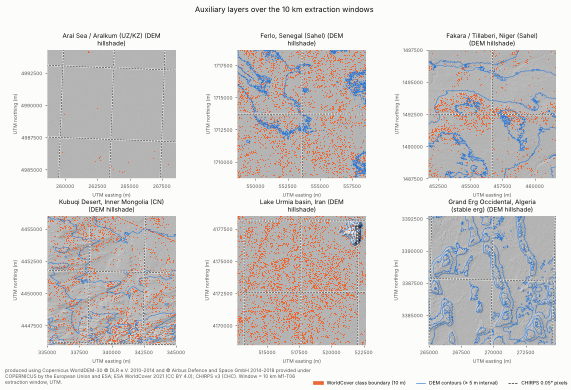

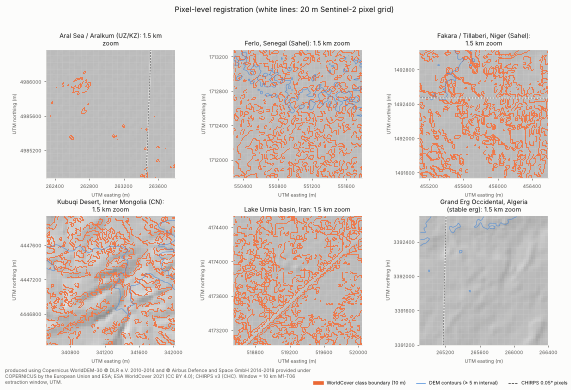

In [6]:
def background(k):
    path = find_composite(get_path(cfg, "data_raw"), k, windows[k])
    if path is not None:
        with rasterio.open(path) as ds:
            names = list(ds.descriptions)
            rgb = np.stack([ds.read(names.index(b) + 1).astype("float32") for b in ("B04", "B03", "B02")], -1)
            valid = ds.read(names.index("valid_count") + 1) > 0
        rgb[~valid] = np.nan
        return stretch_true_colour(rgb / 10000), f"S2 {path.name[:10]}"
    return hillshade(cells[k]["dem"][0], RES), "DEM hillshade"

panels, zooms, years_shown = [], [], set()
wc_res = aux["worldcover_resolution_m"]
for k in aois:
    w = windows[k]
    bg, bg_label = background(k)
    if bg_label.startswith("S2"):
        years_shown.add(bg_label[3:7])
    edges = class_edges(cells[k]["wc"])
    rain_tr = read_tif(rain_paths[k])[1]
    rain_shape = read_tif(rain_paths[k])[0].shape[1:]
    lines = grid_lines_projected(rain_tr, rain_shape, 4326, aois[k]["utm_epsg"])
    common = dict(background=bg, background_extent=w, wc_edges=edges, wc_extent=w, dem=cells[k]["dem"][0],
                  dem_extent=w, chirps_lines=lines)
    panels.append(dict(common, title=f"{aois[k]['name']} ({bg_label})", view=w))
    zpx = int(aux["zoom_m"] // wc_res)
    r, c = busiest_block(edges, zpx)
    x0, y1_ = w[0] + c * wc_res, w[3] - r * wc_res
    view = [x0, y1_ - aux["zoom_m"], x0 + aux["zoom_m"], y1_]
    zooms.append(dict(common, title=f"{aois[k]['name']}: {aux['zoom_m'] / 1000:g} km zoom", view=view, pixel_grid=RES))

attribution = (f"Contains modified Copernicus Sentinel data {', '.join(sorted(years_shown))}, processed by Sentinel Hub; "
               if years_shown else "")
caption = (attribution + "produced using Copernicus WorldDEM-30 © DLR e.V. 2010-2014 and © Airbus Defence and Space "
           "GmbH 2014-2018 provided under COPERNICUS by the European Union and ESA; ESA WorldCover "
           f"{max(wc_paths)} (CC BY 4.0); CHIRPS v3 (CHC). Window = 10 km M1-T06 extraction window, UTM.")
fig = plot_aux_overlay(panels, "Auxiliary layers over the 10 km extraction windows", caption,
                       FIGURES / "m1_aux_overlay.png")
fig2 = plot_aux_overlay(zooms, "Pixel-level registration (white lines: 20 m Sentinel-2 pixel grid)", caption,
                        FIGURES / "m1_aux_overlay_zoom.png")

## 6. What M1-T08 gets from this

- per 20 m pixel: `elevation_m`, `slope_deg`, `aspect_deg`, and the WorldCover majority class (`block_mode` over the 2 × 2 nested 10 m pixels);
- per 100 m cell: WorldCover class fractions (2020 and 2021), monthly rainfall (mm/month) and study-period aridity from the containing 0.05° pixel, plus the AOI's 1991–2020 aridity class.

**Limitations.** Rainfall is the same for every cell inside one 0.05° pixel (two or three distinct values across a window), so it can explain differences between AOIs and years, not within-window patterns. WorldCover is a 2020/2021 snapshot, used as a static covariate and stratifier, not as a change signal. GLO-30 is a 2011–2015 surface model: elevations over the drying Aral Sea and Lake Urmia beds are from that period, not from the study period.

In [7]:
# A per-cell example: the 2 most common classes per AOI and the rainfall of one random cell.
k = list(aois)[int(rng.integers(len(aois)))]
r, c = (int(rng.integers(n)) for n in cells[k]["aridity"].shape)
series = pd.Series(cells[k]["rain"][:, r, c], index=pd.period_range(f"{y0}-01", f"{y1}-12", freq="M"))
print(f"{k}: cell row {r}, col {c}; rainfall {series.groupby(series.index.year).sum().round(0).to_dict()} mm/year; "
      f"aridity {cells[k]['aridity'][r, c]:.3f}")
print("20 m majority WorldCover class shape:", block_mode(cells[k]["wc"], int(RES // wc_res)).shape)

aral: cell row 72, col 1; rainfall {2019: 108.0, 2020: 42.0, 2021: 87.0, 2022: 117.0, 2023: 124.0, 2024: 103.0, 2025: 48.0} mm/year; aridity 0.069
20 m majority WorldCover class shape: (500, 500)
